<a href="https://colab.research.google.com/github/d1ly8/Dilnoza/blob/main/Lab_KMeans_Elbow_Silhouette.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSE206 Fundamental of Machine Learning
## Lab: K-Means Clustering - Choosing the Number of Clusters with the Elbow Method and Silhouette Analysis

**Duration:** 2 hours (two 1-hour sessions)

| Session | Activity | Time |
|---|---|---|
| Session 1 | Guided walkthrough: K-Means, the elbow method, silhouette analysis | 60 min |
| Session 2 | Graded exercises (3 exercises, 100 marks) | 30-40 min |

**By the end of this lab you will be able to:**
1. Explain what clustering is and how the K-Means algorithm works.
2. Write a simple K-Means step by step, and then use the scikit-learn version.
3. Measure how good a clustering is using **inertia** and the **silhouette score**.
4. Choose the number of clusters K using the **elbow method** and **silhouette analysis**.
5. Explain why we scale features before using K-Means.

**How to use this notebook:** run the cells from top to bottom with `Shift + Enter`. If something breaks, use *Runtime > Restart and run all* in Colab.

---
# SESSION 1: Guided Walkthrough

## 1. What is clustering?

So far in this course we mostly had data **with labels** (for example, "spam" or "not spam"). The model learned from the correct answers. This is called **supervised learning**.

In **clustering** we have **no labels**. We only have the data, and we ask the computer:

> "Can you find groups of points that are similar to each other?"

This is called **unsupervised learning**.

**Real-life examples:**
- A shop groups its customers by how much they earn and how much they spend.
- A music app groups songs that sound similar.
- A bank groups transactions to find unusual ones.

**K-Means** is the most popular clustering algorithm. The letter **K** is the number of groups (clusters) we want.

## 2. Import the libraries

We only need four libraries:
- `numpy` for numbers and arrays
- `pandas` for tables
- `matplotlib` for plots
- `sklearn` (scikit-learn) for the K-Means model and the scores

All of them are already installed in Google Colab.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.preprocessing import StandardScaler

print("Libraries loaded")

## 3. Create a simple dataset

To learn, we use a **toy dataset** where we already know the answer. The function `make_blobs` creates points around a few centres ("blobs").

- `n_samples=300` means 300 points
- `centers=4` means 4 groups
- `random_state=42` means we all get the same data

`make_blobs` also returns the true group of each point. In real clustering problems we **do not** have this, so we throw it away using `_`.

In [ ]:
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=42)

print("Shape of X:", X.shape)     # 300 rows (points), 2 columns (features)
print("First 5 points:")
print(X[:5])

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], s=20, color="gray")
plt.title("Our data (no labels)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Question for the class:** How many groups can you see with your eyes?

Most people say **4**. Our goal is to make the computer find these groups by itself, and later to make the computer **choose K by itself** too.

## 4. How does K-Means work?

K-Means repeats two simple steps until nothing changes.

**Step 0 - Start:** choose K random points as the first **centroids** (a centroid is the centre of a cluster).

**Step 1 - Assign:** give every point to its **closest** centroid.

**Step 2 - Update:** move each centroid to the **average position** (mean) of the points that belong to it.

**Repeat** Step 1 and Step 2 until the centroids stop moving.

### How do we measure "closest"?

We use the normal straight-line distance (Euclidean distance). For two points $(x_1, y_1)$ and $(x_2, y_2)$:

$$ d = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2} $$

This is the same distance formula you learned in school.

## 5. K-Means step by step (our own simple version)

Before using scikit-learn, we write K-Means ourselves so you can **see** what happens inside.

### Step 0: choose K random starting centroids
We pick 4 random points from the data and use them as the first centroids.

In [ ]:
K = 4

np.random.seed(3)                                    # so everyone gets the same start
random_rows = np.random.choice(len(X), K, replace=False)
centroids = X[random_rows]

print("Starting centroids:")
print(centroids)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], s=20, color="gray")
plt.scatter(centroids[:, 0], centroids[:, 1], s=250, color="red", marker="X")
plt.title("Step 0: random starting centroids (red X)")
plt.show()

### Steps 1 and 2 written as a function

The function below does **one round** of K-Means:
1. It calculates the distance from every point to every centroid.
2. It gives each point the label of the closest centroid (`argmin` finds the position of the smallest value).
3. It moves each centroid to the mean of its points.

In [ ]:
def kmeans_one_step(X, centroids):
    K = len(centroids)

    # Step 1: distance from each point to each centroid
    distances = np.zeros((len(X), K))
    for j in range(K):
        distances[:, j] = np.sqrt(((X - centroids[j]) ** 2).sum(axis=1))

    # each point joins the closest centroid
    labels = distances.argmin(axis=1)

    # Step 2: move each centroid to the mean of its points
    new_centroids = np.zeros_like(centroids)
    for j in range(K):
        new_centroids[j] = X[labels == j].mean(axis=0)

    return labels, new_centroids

### Run one round at a time

**Run the next cell several times** (press `Shift + Enter` on it again and again). Watch how the red X marks move to the centres of the groups. After a few rounds they stop moving. That means K-Means has **converged** (finished).

In [ ]:
labels, new_centroids = kmeans_one_step(X, centroids)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=20, cmap="viridis")
plt.scatter(centroids[:, 0], centroids[:, 1], s=250, color="red", marker="X", label="old centroids")
plt.scatter(new_centroids[:, 0], new_centroids[:, 1], s=250, color="black", marker="X", label="new centroids")
plt.legend()
plt.title("One round of K-Means")
plt.show()

movement = np.sqrt(((new_centroids - centroids) ** 2).sum())
print("How far the centroids moved this round:", round(movement, 4))

centroids = new_centroids    # save the new centroids for the next round

### The full loop

Instead of running the cell by hand, we put it in a loop that stops when the centroids no longer move. We write it as a function so we can try different random starts (`seed`).

In [ ]:
def my_kmeans(X, K, seed):
    np.random.seed(seed)
    centroids = X[np.random.choice(len(X), K, replace=False)]

    for round_number in range(1, 101):
        labels, new_centroids = kmeans_one_step(X, centroids)
        if np.allclose(new_centroids, centroids):     # centroids did not move
            print("Seed", seed, "- finished after", round_number, "rounds")
            break
        centroids = new_centroids

    return labels, centroids

In [ ]:
labels, centroids = my_kmeans(X, K=4, seed=3)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=20, cmap="viridis")
plt.scatter(centroids[:, 0], centroids[:, 1], s=250, color="red", marker="X")
plt.title("Our own K-Means, seed = 3")
plt.show()

**Look closely: this result is wrong.** The two groups at the top were joined into one cluster, and the group at the bottom was cut into two. The algorithm finished, but it got **stuck** because the random start was bad (three of the four starting centroids were in the same bottom group).

This is an important weakness of K-Means: **the result depends on the random starting centroids.** Let us try a different start.

In [ ]:
labels, centroids = my_kmeans(X, K=4, seed=5)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=20, cmap="viridis")
plt.scatter(centroids[:, 0], centroids[:, 1], s=250, color="red", marker="X")
plt.title("Our own K-Means, seed = 5")
plt.show()

With a better start, K-Means finds the 4 groups correctly. The solution to bad starts is simple: **run K-Means several times with different starts and keep the best result.** Scikit-learn does this for us automatically, as we will see next.

## 6. K-Means with scikit-learn

In practice we do not write K-Means ourselves. Scikit-learn does it in **three lines**. Every scikit-learn model works the same way:

1. **Create** the model: `KMeans(n_clusters=4)`
2. **Fit** the model on the data: `model.fit(X)`
3. **Read** the results

Important settings:
- `n_clusters` is K
- `n_init=10` means "run K-Means 10 times with different random starts and keep the best one". This protects us from a bad random start, like seed 3 above. (The "best" run is the one with the lowest inertia, which we explain in Section 7.)
- `random_state=42` makes the result the same every time

After fitting, the model gives us:
- `model.labels_` is the cluster number of each point (0, 1, 2, 3)
- `model.cluster_centers_` is the position of each centroid
- `model.inertia_` is a score that we explain in the next section

In [ ]:
model = KMeans(n_clusters=4, n_init=10, random_state=42)
model.fit(X)

labels = model.labels_
centers = model.cluster_centers_

print("Cluster of the first 10 points:", labels[:10])
print("Centroids:")
print(centers)

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=20, cmap="viridis")
plt.scatter(centers[:, 0], centers[:, 1], s=250, color="red", marker="X")
plt.title("Scikit-learn K-Means with K = 4")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Predicting new points:** a fitted model can tell us which cluster a **new** point belongs to, using `predict`. It simply finds the closest centroid.

In [ ]:
new_points = np.array([[-8, 7],
                       [ 5, 2]])

print("Clusters of the new points:", model.predict(new_points))

## 7. How good is a clustering? Inertia

**Inertia** (also called WCSS, Within-Cluster Sum of Squares) measures how **tight** the clusters are.

For every point we take its distance to its own centroid, square it, and add everything up:

$$ \text{Inertia} = \sum_{\text{all points}} (\text{distance to own centroid})^2 $$

- **Small inertia** means the points are close to their centroids (tight clusters). Good.
- **Large inertia** means the points are far from their centroids (loose clusters). Bad.

Let us check that our own calculation matches scikit-learn.

In [ ]:
# our own calculation
my_inertia = 0
for j in range(4):
    points_in_cluster = X[labels == j]
    my_inertia += ((points_in_cluster - centers[j]) ** 2).sum()

print("My inertia:          ", round(my_inertia, 2))
print("Scikit-learn inertia:", round(model.inertia_, 2))

### The problem with inertia

Inertia **always goes down** when K goes up. If K = 300 (one cluster per point), every point is its own centroid and inertia is 0. That is "perfect" but useless.

So we **cannot** just pick the K with the smallest inertia. We need a smarter way. This is where the **elbow method** comes in.

## 8. The Elbow Method

**Idea:** try many values of K, record the inertia for each, and draw a line plot.

- At first, adding a cluster makes inertia drop **a lot** (we are splitting real groups).
- After the correct K, adding a cluster makes inertia drop **only a little** (we are just cutting a real group into pieces).

The point where the curve bends, like an **elbow** in your arm, is a good choice for K.

In [ ]:
k_values = range(1, 11)      # K = 1, 2, ..., 10
inertias = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X)
    inertias.append(km.inertia_)
    print("K =", k, "  inertia =", round(km.inertia_, 1))

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters K")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()

**Reading the plot:** the curve falls steeply from K = 1 to K = 4, and after K = 4 it becomes almost flat. The elbow is at **K = 4**, which matches what we saw with our eyes.

**Weakness of the elbow method:** with real data the bend is often **not clear**. Different people may see the elbow at different places. So we use a second method that gives us a clear number: the **silhouette score**.

## 9. Silhouette Analysis

The silhouette score asks two questions for **each point**:

- **a** = average distance from the point to the other points **in its own cluster** (how close are my friends?)
- **b** = average distance from the point to the points in the **nearest other cluster** (how far are my neighbours?)

Then:

$$ s = \frac{b - a}{\max(a, b)} $$

The value of $s$ is always between **-1 and +1**:

| Silhouette value | Meaning |
|---|---|
| close to **+1** | the point is in the right cluster, far from other clusters |
| close to **0** | the point is on the border between two clusters |
| **negative** | the point is probably in the wrong cluster |

The **silhouette score** of a whole clustering is the **average** of $s$ over all points. **Higher is better.**

**Note:** the silhouette score needs at least 2 clusters (with only 1 cluster there is no "other cluster" to compare with), so we start from K = 2.

### A small example by hand

Imagine one point with:
- average distance to its own cluster: a = 1.0
- average distance to the nearest other cluster: b = 4.0

Then s = (4.0 - 1.0) / 4.0 = 0.75. This point is well placed.

In [ ]:
a = 1.0
b = 4.0
s = (b - a) / max(a, b)
print("Silhouette value of this point:", s)

### Silhouette score for different K

We use `silhouette_score(X, labels)` from scikit-learn. It does the calculation above for every point and returns the average.

In [ ]:
k_values_sil = range(2, 11)      # K = 2, 3, ..., 10
sil_scores = []

for k in k_values_sil:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X)
    score = silhouette_score(X, km.labels_)
    sil_scores.append(score)
    print("K =", k, "  silhouette score =", round(score, 3))

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(k_values_sil, sil_scores, marker="o", color="green")
plt.title("Silhouette Score for each K")
plt.xlabel("Number of clusters K")
plt.ylabel("Silhouette score")
plt.xticks(k_values_sil)
plt.grid(True)
plt.show()

best_k = k_values_sil[np.argmax(sil_scores)]
print("Best K according to silhouette:", best_k)

`np.argmax` gives the **position** of the largest value in the list. We use that position to find the matching K.

The highest silhouette score is at **K = 4**. Both methods agree.

### Looking inside: silhouette per cluster

The average score hides details. Silhouette **analysis** also looks at each cluster separately. `silhouette_samples` gives the silhouette value of **every point**, and then we take the average inside each cluster.

Let us compare a good choice (K = 4) with a bad choice (K = 6).

In [ ]:
for k in [4, 6]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X)
    point_scores = silhouette_samples(X, km.labels_)

    cluster_avg = []
    for j in range(k):
        cluster_avg.append(point_scores[km.labels_ == j].mean())

    plt.figure(figsize=(6, 3))
    plt.bar(range(k), cluster_avg)
    plt.axhline(point_scores.mean(), color="red", linestyle="--", label="overall average")
    plt.title("Average silhouette of each cluster, K = " + str(k))
    plt.xlabel("Cluster number")
    plt.ylabel("Silhouette")
    plt.ylim(0, 1)
    plt.legend()
    plt.show()

**What to notice:**
- With **K = 4**, all clusters have a high silhouette. Every cluster is a real group.
- With **K = 6**, some clusters have a much lower silhouette. Those clusters are pieces of a real group that was cut in two, so their points are close to the neighbouring piece.

### Elbow vs silhouette in one table

In [ ]:
summary = pd.DataFrame({
    "K": list(k_values_sil),
    "Inertia": [round(v, 1) for v in inertias[1:]],      # inertias[0] was K = 1
    "Silhouette": [round(v, 3) for v in sil_scores]
})
summary

## 10. Why we must scale the features

K-Means uses **distance**. If one feature has big numbers and another has small numbers, the big one controls everything.

**Example:** customers described by **age** (20 to 70) and **income** (30,000 to 90,000). A difference of 10,000 in income looks much "bigger" than a difference of 30 years in age, only because of the units.

In this made-up data the real groups are **young** and **older** customers, and income is random.

In [ ]:
np.random.seed(0)
age = np.concatenate([np.random.normal(25, 3, 100),      # young group
                      np.random.normal(60, 3, 100)])     # older group
income = np.random.uniform(30000, 90000, 200)            # random income

customers = pd.DataFrame({"Age": age, "Income": income})
customers.head()

In [ ]:
# K-Means WITHOUT scaling
km_raw = KMeans(n_clusters=2, n_init=10, random_state=42)
labels_raw = km_raw.fit_predict(customers)

# K-Means WITH scaling
scaler = StandardScaler()
customers_scaled = scaler.fit_transform(customers)
km_scaled = KMeans(n_clusters=2, n_init=10, random_state=42)
labels_scaled = km_scaled.fit_predict(customers_scaled)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(customers["Age"], customers["Income"], c=labels_raw, cmap="viridis", s=20)
axes[0].set_title("Without scaling: split by income only")
axes[1].scatter(customers["Age"], customers["Income"], c=labels_scaled, cmap="viridis", s=20)
axes[1].set_title("With scaling: split by age (correct)")
for ax in axes:
    ax.set_xlabel("Age")
    ax.set_ylabel("Income")
plt.show()

`fit_predict` is a shortcut: it does `fit` and returns `labels_` in one step.

**StandardScaler** changes every column so that its mean is 0 and its standard deviation is 1. After scaling, age and income are on the same scale, and K-Means can see the real groups.

**Rule:** when your features have different units, **scale them before K-Means**.

## 11. When K-Means does not work well

K-Means assumes clusters are **round blobs** of similar size. If the groups have a strange shape, K-Means cuts them in the wrong place. Here are two "half-moon" groups:

In [ ]:
from sklearn.datasets import make_moons

X_moons, _ = make_moons(n_samples=300, noise=0.05, random_state=42)
moon_labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_moons)

plt.figure(figsize=(6, 4))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=moon_labels, cmap="viridis", s=20)
plt.title("K-Means on two half-moons: wrong split")
plt.show()

Our eyes see two moons, but K-Means draws a straight border across them. For shapes like this, other algorithms (for example DBSCAN) work better. We will meet them later.

## 12. Summary of Session 1

| Idea | What to remember |
|---|---|
| Clustering | Finding groups in data **without labels** (unsupervised learning) |
| K-Means | Repeat: assign points to the closest centroid, then move centroids to the mean |
| Scikit-learn | `KMeans(n_clusters=K, n_init=10, random_state=42)`, then `.fit(X)` |
| Inertia | Sum of squared distances to own centroid. Lower is tighter, but always falls as K grows |
| Elbow method | Plot inertia against K and choose the bend |
| Silhouette score | Between -1 and +1, higher is better, needs K of at least 2. Choose the K with the highest score |
| Scaling | Use `StandardScaler` when features have different units |
| Limitation | K-Means works best on round, similar-sized clusters |

**Workflow for any clustering task:**
1. Look at the data.
2. Scale the features.
3. Try many K values and draw the elbow plot.
4. Calculate the silhouette score for each K.
5. Choose K, fit the final model, and plot the clusters.

You will follow exactly this workflow in Session 2.

---
# SESSION 2: Graded Exercises (100 marks)


**Instructions:**
- Work **independently**. You may use the Session 1 notes above.
- Fill in the blanks marked `___` and the lines marked `# YOUR CODE HERE`.
- Write your written answers in the **Answer** cells (double-click a cell to edit it).
- Run every cell so that your outputs are visible, then save and submit the notebook.
- Suggested time: 30 minutes.

| Exercise | Topic | Marks |
|---|---|---|
| Exercise 1 | Explore, scale and cluster the data | 30 |
| Exercise 2 | Elbow method | 30 |
| Exercise 3 | Silhouette analysis and final model | 40 |
| **Total** | | **100** |

### The dataset: shopping mall customers

A shopping mall wants to group its customers to plan advertising. For each customer we know:
- `Annual_Income`: yearly income in thousands of dollars
- `Spending_Score`: a score from 1 to 100 given by the mall (high means the customer spends a lot)

**Run the cell below to create the data. Do not change it.**

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Recreate the dataset to ensure 'mall' is defined
rng = np.random.default_rng(7)
group_centres = [(25, 20), (25, 80), (55, 50), (90, 20), (90, 80)]
rows = []
for income_c, score_c in group_centres:
    income = rng.normal(income_c, 7, 50)
    score = rng.normal(score_c, 7, 50)
    rows.append(np.column_stack([income, score]))
data = np.clip(np.vstack(rows), [15, 1], [140, 100]).round(0)

mall = pd.DataFrame(data, columns=["Annual_Income", "Spending_Score"])
print("Libraries and 'mall' dataset initialized successfully!")

Libraries and 'mall' dataset initialized successfully!


In [23]:
# DO NOT CHANGE THIS CELL
rng = np.random.default_rng(7)
group_centres = [(25, 20), (25, 80), (55, 50), (90, 20), (90, 80)]
rows = []
for income_c, score_c in group_centres:
    income = rng.normal(income_c, 7, 50)
    score = rng.normal(score_c, 7, 50)
    rows.append(np.column_stack([income, score]))
data = np.clip(np.vstack(rows), [15, 1], [140, 100]).round(0)

mall = pd.DataFrame(data, columns=["Annual_Income", "Spending_Score"])
print("Data is ready")

Data is ready


## Exercise 1: Explore, scale and cluster the data (30 marks)

**1(a) [5 marks]** Print the **shape** of the `mall` table and show its **first 5 rows**.

In [24]:
print("Shape:", mall.shape)
mall.head()

Shape: (250, 2)


,Annual_Income,Spending_Score
0,25.0,25.0
1,27.0,12.0
2,23.0,21.0
3,19.0,24.0
4,22.0,19.0


**1(b) [5 marks]** Draw a scatter plot with `Annual_Income` on the x-axis and `Spending_Score` on the y-axis. Add a title and axis labels.

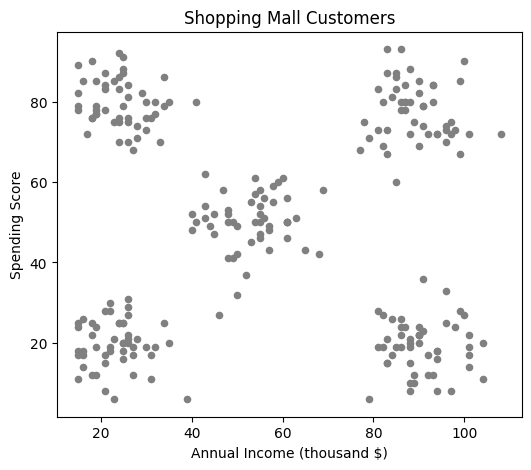

In [25]:
plt.figure(figsize=(6, 5))
plt.scatter(mall["Annual_Income"], mall["Spending_Score"], s=20, color="gray")
plt.title("Shopping Mall Customers")
plt.xlabel("Annual Income (thousand $)")
plt.ylabel("Spending Score")
plt.show()

**1(c) [5 marks]** Scale the data with `StandardScaler`. Store the result in a variable called `X_mall`, then print the first 5 rows of `X_mall`.

In [26]:
scaler = StandardScaler()
X_mall = scaler.fit_transform(mall)

print(X_mall[:5])

[[-1.02795427 -0.88843447]
 [-0.96188188 -1.36545611]
 [-1.09402666 -1.03521036]
 [-1.22617145 -0.92512844]
 [-1.12706286 -1.1085983 ]]


**1(d) [10 marks]** Create a K-Means model with **K = 3**, `n_init=10` and `random_state=42`. Fit it on `X_mall`. Print the **cluster labels of the first 10 customers** and the **inertia**.

In [27]:
model_3 = KMeans(n_clusters=3, n_init=10, random_state=42)
model_3.fit(X_mall)

print("Labels of first 10 customers:", model_3.labels_[:10])
print("Inertia:", model_3.inertia_)

Labels of first 10 customers: [0 0 0 0 0 0 0 0 0 0]
Inertia: 174.25982047273638


**1(e) [5 marks]** Draw the same scatter plot as in 1(b), but colour the points by the cluster labels of `model_3`.

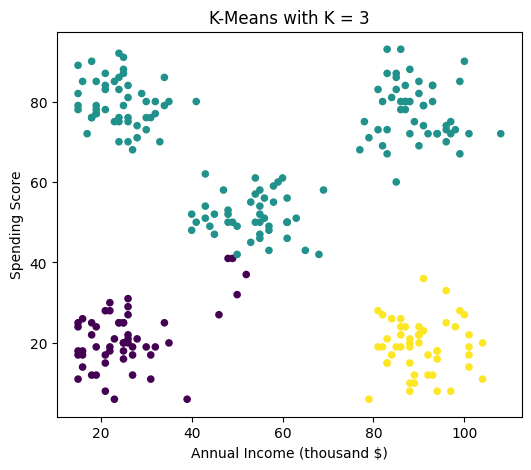

In [28]:
plt.figure(figsize=(6, 5))
plt.scatter(mall["Annual_Income"], mall["Spending_Score"], c=model_3.labels_, cmap="viridis", s=20)
plt.title("K-Means with K = 3")
plt.xlabel("Annual Income (thousand $)")
plt.ylabel("Spending Score")
plt.show()

## Exercise 2: Elbow method (30 marks)

**2(a) [15 marks]** Write a loop for K = 1 to 10. For each K, fit a K-Means model on `X_mall` (use `n_init=10, random_state=42`) and add its inertia to the list `mall_inertias`. Print K and the inertia in each round.

In [29]:
k_list = range(1, 11)
mall_inertias = []

for k in k_list:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_mall)
    mall_inertias.append(km.inertia_)
    print("K =", k, "  inertia =", round(km.inertia_, 1))

K = 1   inertia = 500.0
K = 2   inertia = 289.2
K = 3   inertia = 174.3
K = 4   inertia = 74.2
K = 5   inertia = 25.1
K = 6   inertia = 22.5
K = 7   inertia = 20.8
K = 8   inertia = 18.7
K = 9   inertia = 17.1
K = 10   inertia = 15.6


**2(b) [10 marks]** Draw the elbow plot: K on the x-axis, inertia on the y-axis, with markers. Add a title, axis labels and a grid.

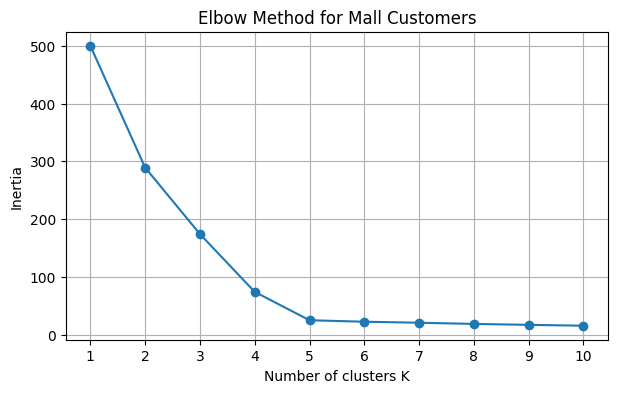

In [30]:
plt.figure(figsize=(7, 4))
plt.plot(k_list, mall_inertias, marker="o")
plt.title("Elbow Method for Mall Customers")
plt.xlabel("Number of clusters K")
plt.ylabel("Inertia")
plt.xticks(k_list)
plt.grid(True)
plt.show()

**2(c) [5 marks]** Written answer: Where is the elbow? Which K do you choose, and why?

**Answer:**

The elbow is at **K = 5**. We choose K = 5 because up to K = 5, the inertia decreases significantly, but after K = 5, the rate of decrease slows down and the plot becomes much flatter (forming an 'elbow' shape).

## Exercise 3: Silhouette analysis and final model (40 marks)

**3(a) [15 marks]** Write a loop for K = 2 to 10. For each K, fit a K-Means model on `X_mall` (use `n_init=10, random_state=42`), calculate the silhouette score, and add it to the list `mall_sil`. Print K and the score in each round.

In [31]:
k_list_sil = range(2, 11)
mall_sil = []

for k in k_list_sil:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_mall)
    score = silhouette_score(X_mall, km.labels_)
    mall_sil.append(score)
    print("K =", k, "  silhouette =", round(score, 3))

K = 2   silhouette = 0.415
K = 3   silhouette = 0.509
K = 4   silhouette = 0.64
K = 5   silhouette = 0.725
K = 6   silhouette = 0.66
K = 7   silhouette = 0.581
K = 8   silhouette = 0.514
K = 9   silhouette = 0.431
K = 10   silhouette = 0.354


**3(b) [10 marks]** Plot the silhouette score against K. Then use `np.argmax` to find the best K automatically and store it in `best_k`.

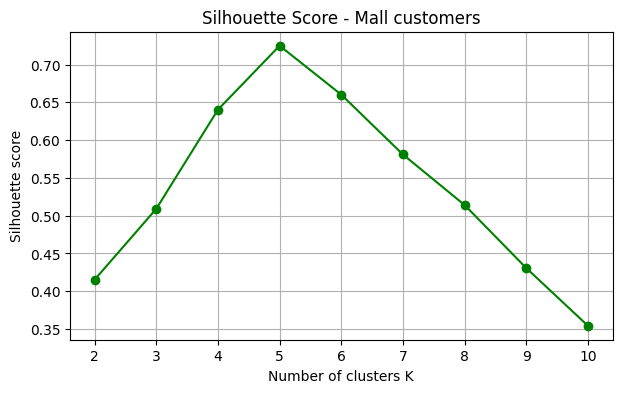

Best K: 5


In [32]:
plt.figure(figsize=(7, 4))
plt.plot(k_list_sil, mall_sil, marker="o", color="green")
plt.title("Silhouette Score - Mall customers")
plt.xlabel("Number of clusters K")
plt.ylabel("Silhouette score")
plt.grid(True)
plt.show()

best_k = k_list_sil[np.argmax(mall_sil)]
print("Best K:", best_k)

**3(c) [10 marks]** Fit the **final model** with `best_k` clusters on `X_mall`. Draw a scatter plot of the customers (original `Annual_Income` and `Spending_Score`) coloured by the final cluster labels.

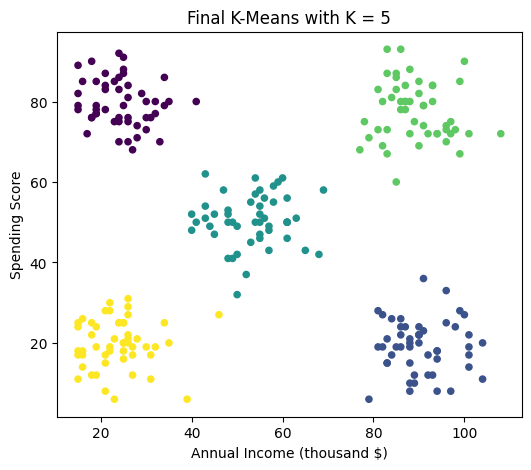

In [33]:
final_model = KMeans(n_clusters=best_k, n_init=10, random_state=42)
final_labels = final_model.fit_predict(X_mall)

plt.figure(figsize=(6, 5))
plt.scatter(mall["Annual_Income"], mall["Spending_Score"], c=final_labels, cmap="viridis", s=20)
plt.title(f"Final K-Means with K = {best_k}")
plt.xlabel("Annual Income (thousand $)")
plt.ylabel("Spending Score")
plt.show()

**3(d) [5 marks]** Written answer:
1. Do the elbow method and the silhouette score suggest the same K?
2. Why does the silhouette loop start from K = 2 and not K = 1?

**Answer:**

1. It depends the results. If both methods gave you the same optimal K, the answer is Yes. If they gave different K values, the answer is No.

2. The silhouette loop starts from K = 2 because K = 1 has only one cluster. Silhouette score requires at least two clusters to compare how well data points fit within their own cluster versus other clusters.